# Fraud radar (v2)

<a href="https://colab.research.google.com/github/Aadharsh21/ML-Projects/blob/main/notebooks/02-fraud-detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Flag fraudulent card transactions in a stream where fewer than 2 in 1,000 are fraud.

The first version ([`notebooks/v1/CREDITFRAUD.ipynb`](v1/CREDITFRAUD.ipynb)) found that a neural network with
99.9% accuracy caught only 28% of fraud, then undersampled the legitimate transactions to a 50/50 mix, trained a
logistic regression and reported **88% of fraud caught** on a balanced test sample. That last number is the trap
this notebook is about: a fraud team never sees a 50/50 stream.

| Same v1 procedure, graded two ways | 50/50 sample (v1's way) | Real stream |
|---|---|---|
| Fraud caught | 85 of 94 | 85 of 94 |
| False alarms | 4 | **3,740** in 9.3 hours |

v2 grades everything on the real stream, picks thresholds by money rather than accuracy, and uses LightGBM:

| On the last 71,202 transactions (94 frauds) | v1 | v2 |
|---|---|---|
| Average precision (PR-AUC) | 0.711 | **0.803** |
| Fraud caught at a 0.5 threshold | 85 of 94 | 70 of 94 |
| False alarms | 3,740 | **8** |
| Fraud blocked minus $5 per review | $-10,274 | **$7,803** |

Code: [`ml/fraud.py`](../ml/fraud.py).

In [1]:
# Setup: runs from a local clone, or in Google Colab (it clones the repo first)
import os, sys
if "google.colab" in sys.modules:
    if not os.path.exists("ML-Projects"):
        !git clone -q https://github.com/Aadharsh21/ML-Projects.git
    %cd ML-Projects
    %pip install -q "lightgbm>=4.3"
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.metrics import average_precision_score, precision_recall_curve, confusion_matrix

from ml import data, fraud, plotting as P
from ml.evaluation import binary_metrics, bootstrap_ci

P.style()
pd.set_option("display.precision", 3)

## 1. The data

[Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud): 284,807 transactions made by
European cardholders over two days in September 2013. To protect the cardholders, 28 of the columns (`V1` to `V28`)
are anonymous PCA components. The only readable columns are `Time` (seconds since the first transaction), `Amount`
and the label `Class`.

In [3]:
df = data.load_creditcard()
n_fraud = int(df["Class"].sum())
print(f"{len(df):,} transactions, {n_fraud} frauds ({n_fraud / len(df):.3%})")
print(f"Always answering 'legitimate' is {1 - n_fraud / len(df):.2%} accurate and catches nothing.")
df[["Time", "V1", "V2", "V3", "Amount", "Class"]].head(3)

284,807 transactions, 492 frauds (0.173%)
Always answering 'legitimate' is 99.83% accurate and catches nothing.


,Time,V1,V2,V3,Amount,Class
0,0.0,-1.360,-0.073,2.536,149.62,0
1,0.0,1.192,0.266,0.166,2.69,0
2,1.0,-1.358,-1.340,1.773,378.66,0


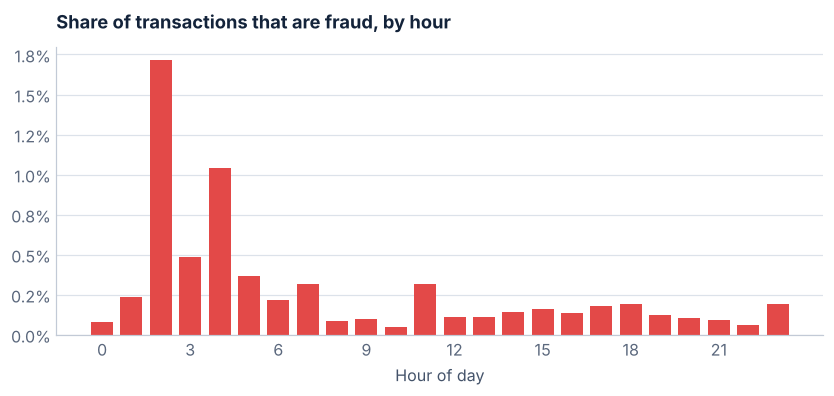

,count,25%,50%,75%,95%,max
Legitimate,284315.0,5.65,22.00,77.05,364.409,25691.16
Fraud,492.0,1.00,9.25,105.89,640.905,2125.87


In [4]:
hour = ((df["Time"] % 86400) // 3600).astype(int)
by_hour = df.groupby(hour)["Class"].agg(["mean", "sum", "size"])
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(by_hour.index, by_hour["mean"], color=P.RED, width=0.75)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=1))
ax.set_xticks(range(0, 24, 3))
ax.set_xlabel("Hour of day")
ax.set_title("Share of transactions that are fraud, by hour")
ax.grid(axis="x", visible=False)
plt.show()

amounts = df.groupby("Class")["Amount"].describe(percentiles=[0.25, 0.5, 0.75, 0.95])
amounts.index = ["Legitimate", "Fraud"]
amounts[["count", "25%", "50%", "75%", "95%", "max"]]

Fraud is far more common at night, when there are few legitimate transactions, which is why v2 gives the model the
hour of day. Fraudulent amounts are mostly small (half are under $10, often test charges) with a long tail.

## 2. A split that respects time

v1 shuffled the rows before splitting, so the model trained on transactions from minutes after the ones it was
tested on. In production a model only ever scores the future, so v2 sorts by time and splits chronologically:
the first 60% to train, the next 15% to decide when to stop training, and the last 25% to test.

In [5]:
X = fraud.features(df)
y = df["Class"].to_numpy()
s = fraud.split(df)
tr, va, te = s["train"], s["val"], s["test"]
pd.DataFrame({
    name: {"transactions": int(mask.sum()), "frauds": int(y[mask].sum()),
           "from hour": round(df.loc[mask, "Time"].min() / 3600, 1),
           "to hour": round(df.loc[mask, "Time"].max() / 3600, 1)}
    for name, mask in s.items()
}).T

,transactions,frauds,from hour,to hour
train,170884.0,360.0,0.0,33.4
val,42721.0,38.0,33.4,38.7
test,71202.0,94.0,38.7,48.0


Raw `Time` is left out of the features: every test transaction comes after every training one, so the model could
only extrapolate on it. Hour of day goes in instead, as a point on a circle (sine and cosine) so 11pm sits next to
midnight. `Amount` goes in as `log(1 + amount)`.

## 3. The v1 trap, reproduced

Here is v1's procedure on the new split: keep every training fraud plus the same number of random legitimate
transactions, then fit a logistic regression. It is then graded twice, the way v1 did (on a 50/50 sample of the
test window) and on the real test stream.

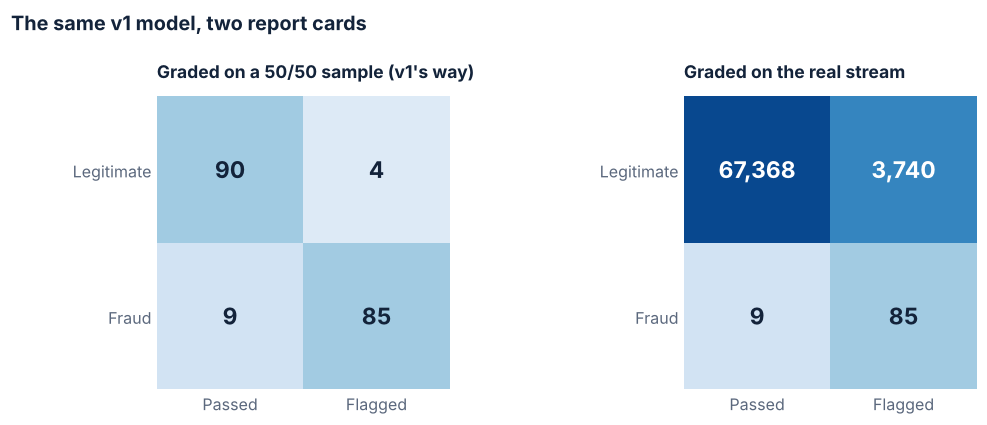

In [6]:
test = df[te]
yt = y[te]
amount = test["Amount"].to_numpy()

balanced = fraud.undersample(df[tr])
v1 = fraud.v1_model().fit(balanced[fraud.V1_COLUMNS], balanced["Class"])
p_v1 = v1.predict_proba(test[fraud.V1_COLUMNS])[:, 1]

rng = np.random.default_rng(3)
fraud_idx = np.flatnonzero(yt == 1)
legit_idx = rng.choice(np.flatnonzero(yt == 0), size=len(fraud_idx), replace=False)
sample = np.concatenate([fraud_idx, legit_idx])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
for ax, (title, idx) in zip(axes, [("Graded on a 50/50 sample (v1's way)", sample),
                                    ("Graded on the real stream", np.arange(len(yt)))]):
    cm = confusion_matrix(yt[idx], p_v1[idx] >= 0.5)
    ax.imshow(np.log1p(cm), cmap="Blues", vmin=0, vmax=np.log1p(len(yt)) * 1.1)
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{v:,}", ha="center", va="center", fontsize=15, fontweight="bold",
                color="white" if np.log1p(v) > np.log1p(len(yt)) * 0.55 else P.INK)
    ax.set_xticks([0, 1], ["Passed", "Flagged"])
    ax.set_yticks([0, 1], ["Legitimate", "Fraud"])
    ax.set_title(title, fontsize=11.5)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
fig.suptitle("The same v1 model, two report cards", x=0.02, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
P.save(fig, "fraud-two-report-cards.png")
plt.show()

In [7]:
real = fraud.money(yt, amount, p_v1 >= 0.5, fraud.REVIEW_COST)
hours = (test["Time"].max() - test["Time"].min()) / 3600
print(f"On the real stream v1 raises {real['alerts']:,} alerts in {hours:.1f} hours "
      f"({real['alerts'] / hours:.0f} an hour) to stop ${real['blocked']:,.0f} of fraud.")
print(f"At $5 of analyst time per alert that is a net loss of ${-real['net_savings']:,.0f}.")

On the real stream v1 raises 3,825 alerts in 9.3 hours (411 an hour) to stop $8,851 of fraud.
At $5 of analyst time per alert that is a net loss of $10,274.


On a 50/50 sample, every false alarm looks rare because there are only as many legitimate transactions as frauds.
On the real stream there are 750 legitimate transactions for every fraud, so the same 5% false-alarm rate turns into
thousands of alerts. Fraud models have to be graded at the true class balance, with metrics that ignore the easy
true negatives: precision, recall and average precision (the area under the precision-recall curve).

## 4. v2: gradient boosted trees on the full stream

LightGBM trains on all 170,884 training transactions at their natural balance, so its scores are honest
probabilities. Training stops when average precision on the validation window stops improving.

In [8]:
train_set = lgb.Dataset(X[tr], y[tr], free_raw_data=False)
val_set = lgb.Dataset(X[va], y[va], reference=train_set)
booster = lgb.train(fraud.LGB_PARAMS, train_set, num_boost_round=5000, valid_sets=[val_set],
                    callbacks=[lgb.early_stopping(300, verbose=False)])
p_v2 = booster.predict(X[te], num_iteration=booster.best_iteration)
print(f"{booster.best_iteration} trees")

p_lrw = fraud.weighted_logistic().fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]

890 trees


## 5. Results on the test stream

In [9]:
rows = {}
for name, p in [("v1: undersampled logistic regression", p_v1),
                ("Logistic regression, class-weighted", p_lrw),
                ("v2: LightGBM", p_v2)]:
    m = binary_metrics(yt, p, 0.5)
    money = fraud.money(yt, amount, p >= 0.5, fraud.REVIEW_COST)
    rows[name] = {
        "avg precision": f"{m['avg_precision']:.3f}",
        "ROC AUC": f"{m['roc_auc']:.3f}",
        "caught": f"{m['tp']} of {m['tp'] + m['fn']}",
        "false alarms": f"{m['fp']:,}",
        "alerts per hour": f"{money['alerts'] / hours:.1f}",
        "fraud blocked": P.dollars(money["blocked"]),
        "net savings": P.dollars(money["net_savings"]),
    }
results = pd.DataFrame(rows).T
results

,avg precision,ROC AUC,caught,false alarms,alerts per hour,fraud blocked,net savings
v1: undersampled logistic regression,0.711,0.980,85 of 94,"3,740",411.4,"$8,851","-$10,274"
"Logistic regression, class-weighted",0.753,0.978,84 of 94,"3,539",389.7,"$8,851","-$9,264"
v2: LightGBM,0.803,0.980,70 of 94,8,8.4,"$8,193","$7,803"


In [10]:
lo, hi = bootstrap_ci(yt, p_v2, average_precision_score, n=300)
print(f"v2 average precision {average_precision_score(yt, p_v2):.3f}, 95% bootstrap interval {lo:.3f} to {hi:.3f}")
print(f"(only {yt.sum()} frauds in the test window, so every metric here is noisy)")

v2 average precision 0.803, 95% bootstrap interval 0.710 to 0.873
(only 94 frauds in the test window, so every metric here is noisy)


ROC AUC barely separates the models: with 71,000 easy negatives it rewards everyone. Average precision does, and so
do the counts that matter to a fraud team: v2 catches three quarters of the fraud while raising about eight alerts
an hour, and nine in ten of them are real fraud.

## 6. Precision and recall at every threshold

Each curve sweeps the alert threshold from strict (left: few alerts, almost all real) to loose (right: catch more,
but drown in false alarms). The dots mark a 0.5 threshold.

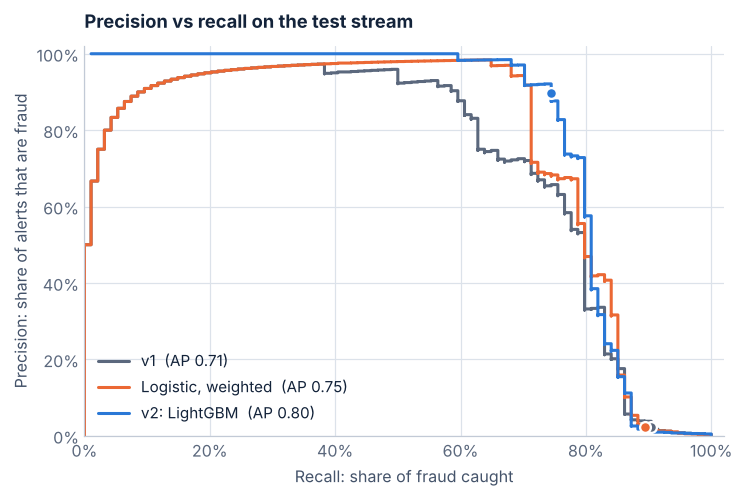

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for name, p, color in [("v1", p_v1, P.INK_3), ("Logistic, weighted", p_lrw, P.ORANGE), ("v2: LightGBM", p_v2, P.BLUE)]:
    precision, recall, _ = precision_recall_curve(yt, p)
    # drop scikit-learn's closing (recall 0, precision 1) point and draw the curve as steps
    ax.step(recall[:-1], precision[:-1], where="post", color=color, lw=2,
            label=f"{name}  (AP {average_precision_score(yt, p):.2f})")
    pred = p >= 0.5
    tp = (pred & (yt == 1)).sum()
    ax.scatter([tp / yt.sum()], [tp / max(pred.sum(), 1)], color=color, s=50, ec="white", lw=1.5, zorder=3)
ax.set_xlabel("Recall: share of fraud caught")
ax.set_ylabel("Precision: share of alerts that are fraud")
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.02)
for a in (ax.xaxis, ax.yaxis):
    a.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.legend(loc="lower left")
ax.set_title("Precision vs recall on the test stream")
P.save(fig, "fraud-precision-recall.png")
plt.show()

## 7. Choosing the threshold by money

A threshold is a business decision. Suppose every alert costs an analyst $5 to review, and every fraud that gets
through costs its amount. Net savings is then the fraud blocked minus the cost of reviews. The best threshold
depends on the review cost, but v2's curve is flat near its peak, so the exact choice matters little.

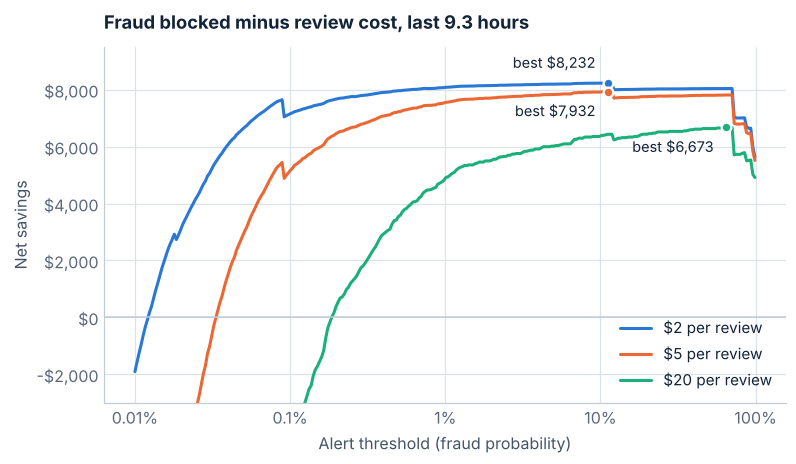

In [12]:
thresholds = np.logspace(-4, np.log10(0.99), 300)
fig, ax = plt.subplots(figsize=(8, 4.2))
for cost, color, dy in [(2, P.BLUE, 10), (5, P.ORANGE, -16), (20, P.AQUA, -16)]:
    net = [fraud.money(yt, amount, p_v2 >= t, cost)["net_savings"] for t in thresholds]
    best = int(np.argmax(net))
    ax.plot(thresholds, net, color=color, label=f"${cost} per review")
    ax.scatter([thresholds[best]], [net[best]], color=color, s=40, ec="white", lw=1.5, zorder=3)
    ax.annotate(f"best {P.dollars(net[best])}", (thresholds[best], net[best]),
                xytext=(-8, dy), textcoords="offset points", ha="right", color=P.INK, fontsize=9.5)
ax.axhline(0, color=P.GRAY, lw=1)
ax.set_xscale("log")
ax.set_xticks([1e-4, 1e-3, 1e-2, 1e-1, 1], ["0.01%", "0.1%", "1%", "10%", "100%"])
ax.minorticks_off()
ax.set_xlabel("Alert threshold (fraud probability)")
ax.set_ylabel("Net savings")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(P.dollars))
ax.legend(loc="lower right")
ax.set_ylim(-3000, 9500)
ax.set_title(f"Fraud blocked minus review cost, last {hours:.1f} hours")
P.save(fig, "fraud-savings.png")
plt.show()

A threshold treats a $1 fraud and a $1,000 fraud the same. An alternative rule flags a transaction only when its
**expected loss**, P(fraud) x amount, is larger than the cost of reviewing it:

In [13]:
rules = {
    "Probability above 0.5": p_v2 >= 0.5,
    "Expected loss above $5": p_v2 * amount >= fraud.REVIEW_COST,
}
def describe_rule(flags):
    money = fraud.money(yt, amount, flags, fraud.REVIEW_COST)
    return {"alerts": money["alerts"], "frauds caught": int((flags & (yt == 1)).sum()),
            "fraud blocked": P.dollars(money["blocked"]), "review cost": P.dollars(money["review_cost"]),
            "net savings": P.dollars(money["net_savings"])}

pd.DataFrame({name: describe_rule(flags) for name, flags in rules.items()}).T

,alerts,frauds caught,fraud blocked,review cost,net savings
Probability above 0.5,78,70,"$8,193",$390,"$7,803"
Expected loss above $5,65,33,"$8,384",$325,"$8,059"


The expected-loss rule catches fewer frauds but more of the money: it lets small test charges through, which cost
more to review than they are worth. Which rule is right depends on what a missed fraud costs beyond its amount
(an angry customer, a compromised card), which is exactly the kind of question the threshold should be set by.

## 8. What the model looks at

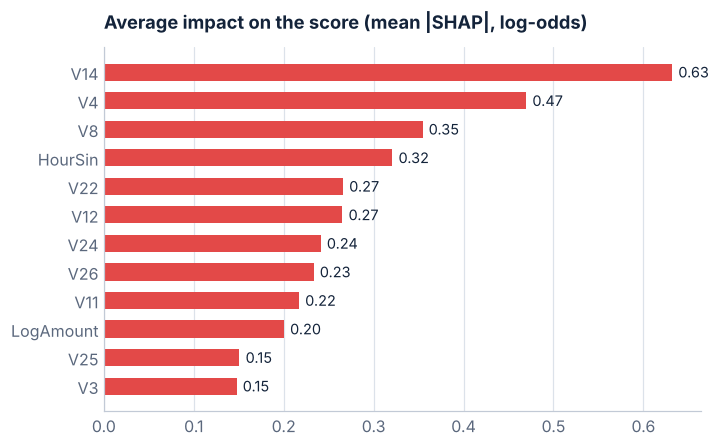

In [14]:
contrib = booster.predict(X[te], num_iteration=booster.best_iteration, pred_contrib=True)
impact = pd.Series(np.abs(contrib[:, :-1]).mean(axis=0), index=fraud.FEATURES).sort_values().tail(12)
fig, ax = plt.subplots(figsize=(7, 4.3))
bars = ax.barh(impact.index, impact.values, color=P.RED, height=0.6)
P.label_bars(ax, bars, "{:.2f}")
ax.grid(axis="y", visible=False)
ax.set_title("Average impact on the score (mean |SHAP|, log-odds)")
plt.show()

`V14`, `V4` and `V8` carry most of the signal. Because the bank anonymised the features with PCA, they can't be
read as "unusual merchant" or "new device", which limits how much an analyst could learn from an explanation.
Hour of day is the most useful readable feature.

## 9. One catch and one miss

The most confident catch, and the fraud the model was most sure was legitimate. Contributions are in log-odds,
starting from the average score of a transaction, which is very low because fraud is rare.

In [15]:
order = np.argsort(-p_v2)
caught = next(i for i in order if yt[i] == 1)
missed = next(i for i in order[::-1] if yt[i] == 1)
for title, i in [("Caught", caught), ("Missed", missed)]:
    phi = contrib[i]
    top = pd.Series(phi[:-1], index=fraud.FEATURES).sort_values(key=np.abs, ascending=False).head(4)
    print(f"{title}: ${amount[i]:,.2f} at {(test['Time'].iloc[i] % 86400) / 3600:.1f}h, score {p_v2[i]:.4f} "
          f"(starting point {phi[-1]:+.2f} log-odds). Biggest pushes: "
          + ", ".join(f"{k} {v:+.2f}" for k, v in top.items()))

Caught: $1.00 at 15.8h, score 0.9996 (starting point -11.99 log-odds). Biggest pushes: V14 +4.83, V4 +2.75, V17 +2.55, V12 +2.26
Missed: $4.49 at 15.3h, score 0.0000 (starting point -11.99 log-odds). Biggest pushes: V14 +1.10, V22 -0.38, V11 +0.34, HourSin +0.30


## 10. Export for the browser

`python -m ml fraud` writes the model, the scored test stream for v1 and v2 (time, amount, label and score of all
71,202 transactions) and full feature rows for every transaction worth inspecting to `web/public/data/fraud/`.
A web page can replay the stream, recompute every number in this notebook for any threshold, and explain a flagged
transaction with the same TreeSHAP values as above.

## Limitations

- **Small test set.** 94 frauds give a wide confidence interval on every metric; a few frauds either way moves
  recall by several points.
- **Two days of data.** Real fraud patterns drift week to week; a production model would be retrained and monitored
  for drift, and labels (chargebacks) arrive days late.
- **Anonymous features.** The PCA columns make explanations hard to act on.
- **The cost model is a sketch.** $5 per review and "amount lost" ignore customer friction from false alarms and the
  wider cost of a compromised card.